In [455]:
import pandas as pd
from sqlalchemy import create_engine
import time
import requests
import pandas as pd

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL



DB_CONFIG = {
    "host": "aws-0-eu-west-1.pooler.supabase.com",
    "port": 6543,
    "database": "postgres",
    "user": "postgres.palaoxigjbvbrgdnbstd",
    "password": "@ghZ2XjxsdL_*m*"
}



url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_CONFIG["user"],
    password=DB_CONFIG["password"],
    host=DB_CONFIG["host"],
    port=DB_CONFIG["port"],
    database=DB_CONFIG["database"]
)

engine = create_engine(url)

In [457]:
import pandas as pd

#accessibilità
query_access = """
SELECT *
FROM panel_como_multi_amenity
union select * from panel_sondrio_multi_amenity
union select * from panel_lecco_multi_amenity
union select * from panel_bergamo_multi_amenity
"""

#meteo
query_meteo = """
select * from como_weather_1980_2025
union select * from sondrio_weather_1980_2025
union select * from lecco_weather_1980_2020
union select * from bergamo_weather_1980_2020
"""
#demo istat
query_demo = """
select * from storica_demo sd where provincia  in ('Como','Sondrio','Lecco','Bergamo')
"""

query_turismo = """
select * from flussi_turistici sd where provincia  in ('COMO','SONDRIO','LECCO','BERGAMO')
"""

query_anagrafica_comuni = """
select * from anagrafica_comuni
"""

access = pd.read_sql(query_access, engine)
meteo = pd.read_sql(query_meteo, engine)
demo = pd.read_sql(query_demo, engine)
turismo = pd.read_sql(query_turismo, engine)
anag = pd.read_sql(query_anagrafica_comuni, engine)

print(access.shape)
print(meteo.shape)
print(demo.shape)
print(turismo.shape)

(30305, 5)
(191545, 6)
(19569, 42)
(2236, 28)


In [458]:
print(anag.shape)

(7894, 42)


In [459]:
turismo.head()

,cod_reg,regione,cod_prov,provincia,comune,cod_istat,flag,arrivi_acc_tot_res,arrivi_acc_tot_nonres,arrivi_acc_tot,...,presenze_night_tot,Presenze Nights spent Hotels and similar establishments Resid,Presenze Nights spent Hotels and similar establishments - Non,Presenze Nights spent Hotels and similar establishments - Tota,presenze_altri_res,Presenze Nights spent Other accomm. establishments - Non resid,presenze_altri_tot,anno,id_flusso,codice_comune_normalizzato
0,30,LOMBARDIA,13,COMO,Altri comuni della provincia di COMO,None,None,25697,None,42830,...,71766,(*),(*),(*),(*),(*),(*),2024,013777_2024,None
1,30,LOMBARDIA,14,SONDRIO,Altri comuni della provincia di SONDRIO,None,None,10444,None,14098,...,23026,(*),(*),(*),(*),(*),(*),2024,014777_2024,None
2,30,LOMBARDIA,16,BERGAMO,Altri comuni della provincia di BERGAMO,None,None,64487,None,110671,...,189675,(*),(*),(*),(*),(*),(*),2024,016777_2024,None
3,30,LOMBARDIA,97,LECCO,Altri comuni della provincia di LECCO,None,None,10455,None,20370,...,37275,(*),(*),(*),(*),(*),(*),2024,097777_2024,None
4,30,LOMBARDIA,13,COMO,Altri comuni della provincia di COMO,None,None,20527,None,55978,...,151698,(*),(*),(*),(*),(*),(*),2023,0_2023,None


In [460]:
turismo = turismo[['comune', 'anno', 'arrivi_acc_tot', 'presenze_night_tot']]

In [461]:
anag.columns

Index(['codice_regione',
       'Codice dell'Unità territoriale sovracomunale \n(valida a fini s',
       'codice_provincia', 'Progressivo del Comune (2)', 'codice_comune',
       'Denominazione (Italiana e straniera)', 'Denominazione in italiano',
       'Denominazione altra lingua', 'Codice Ripartizione Geografica',
       'Ripartizione geografica', 'Denominazione Regione',
       'Denominazione_province',
       'Tipologia di Unità territoriale sovracomunale ',
       'Flag Comune capoluogo di Provincia/Città metropolitana/libero ',
       'Sigla automobilistica', 'Codice Comune formato numerico',
       'Codice Comune numerico con 107 Province (dal 2017 al 2025)',
       'Codice Comune numerico con 110 Province (dal 2010 al 2016)',
       'Codice Comune numerico con 107 Province (dal 2006 al 2009)',
       'Codice Comune numerico con 103 Province (dal 1995 al 2005)',
       'Codice Catastale del Comune', 'Codice NUTS1 2021',
       'Codice NUTS2 2021 (3) ', 'Codice NUTS3 2021', 'Co

In [462]:
anag = anag[['Denominazione in italiano','0-299 (%)', '300-599 (%)', '600-899 (%)', '900-1199 (%)',
       '1200-1499 (%)', '1500-1999 (%)', '2000-2499 (%)', '>=2500 (%)',
       'comune_montano', 'Fascia_Prevalente', 'Classificazione_Finale','latitudine']]

In [463]:
turismo.head()

,comune,anno,arrivi_acc_tot,presenze_night_tot
0,Altri comuni della provincia di COMO,2024,42830,71766
1,Altri comuni della provincia di SONDRIO,2024,14098,23026
2,Altri comuni della provincia di BERGAMO,2024,110671,189675
3,Altri comuni della provincia di LECCO,2024,20370,37275
4,Altri comuni della provincia di COMO,2023,55978,151698


In [464]:
access = (
    access.pivot(
        index=["COMUNE", "year"],
        columns="amenity",
        values="time_min"
    )
    .reset_index()
)
access

amenity,COMUNE,year,hospital,kindergarten,school,station,supermarket
0,Abbadia Lariana,2015,7.224523,9.473125,6.373296,7.432888,6.459780
1,Abbadia Lariana,2016,7.233248,6.391340,6.441792,7.205717,6.490058
2,Abbadia Lariana,2017,7.222412,6.133231,6.398749,6.991035,6.069904
3,Abbadia Lariana,2018,7.248086,6.325469,6.437911,7.171767,5.842133
4,Abbadia Lariana,2019,7.253214,6.396346,6.219417,7.216465,5.835707
...,...,...,...,...,...,...,...
6056,Zogno,2021,2.874728,3.198502,0.000000,7.415724,3.023175
6057,Zogno,2022,2.805909,3.317091,0.525243,7.508246,2.953520
6058,Zogno,2023,2.809469,3.323815,0.525597,7.498950,2.957387
6059,Zogno,2024,2.810021,3.327154,0.526115,7.497712,2.958094


In [465]:
access["comune_norm"] = (
    access["COMUNE"]
    .str.upper()
    .str.strip()
)

meteo["comune_norm"] = (
    meteo["comune"]
    .str.upper()
    .str.strip()
)

demo["comune_norm"] = (
    demo["comune_norm"]
    .str.upper()
    .str.strip()
)

turismo["comune_norm"] = (
    turismo["comune"]
    .str.upper()
    .str.strip()
)

anag["comune_norm"] = ( anag["Denominazione in italiano"]
    .str.upper()
    .str.strip())

In [466]:
turismo.head()

,comune,anno,arrivi_acc_tot,presenze_night_tot,comune_norm
0,Altri comuni della provincia di COMO,2024,42830,71766,ALTRI COMUNI DELLA PROVINCIA DI COMO
1,Altri comuni della provincia di SONDRIO,2024,14098,23026,ALTRI COMUNI DELLA PROVINCIA DI SONDRIO
2,Altri comuni della provincia di BERGAMO,2024,110671,189675,ALTRI COMUNI DELLA PROVINCIA DI BERGAMO
3,Altri comuni della provincia di LECCO,2024,20370,37275,ALTRI COMUNI DELLA PROVINCIA DI LECCO
4,Altri comuni della provincia di COMO,2023,55978,151698,ALTRI COMUNI DELLA PROVINCIA DI COMO


Preparo la tabella meteo

In [467]:
##aggrego il meteo per anno
meteo_year = (
    meteo
    .groupby(
        ["comune","year"],
        as_index=False
    )
    .agg(
        temp_mean=("temperature_mean","mean"),
        rain_sum=("rain_sum","sum"),
        snow_sum=("snowfall_sum","sum")
    )
)

In [468]:
##std tempreratura e pioggia
meteo_var = (
    meteo
    .groupby(
        ["comune","year"],
        as_index=False
    )
    .agg(
        temp_sd=("temperature_mean","std"),
        rain_sd=("rain_sum","std")
    )
)

In [469]:
meteo_year = meteo_year.merge(
    meteo_var,
    on=["comune","year"]
)

In [470]:
##numero mesi con neve
snow_months = (
    meteo
    .assign(
        snow_month=lambda x:
        (x["snowfall_sum"] > 0).astype(int)
    )
    .groupby(
        ["comune","year"],
        as_index=False
    )
    .agg(
        n_snow_months=("snow_month","sum")
    )
)

In [471]:
meteo_year = meteo_year.merge(
    snow_months,
    on=["comune","year"]
)

In [472]:
##temp media invernale
winter = meteo[
    meteo["month"].isin([12,1,2])
]

winter_temp = (
    winter
    .groupby(
        ["comune","year"],
        as_index=False
    )
    .agg(
        winter_temp_mean=("temperature_mean","mean")
    )
)

In [473]:
#pioggia estrema: mesi sopra il 90 percentile
threshold = meteo["rain_sum"].quantile(0.90)

meteo["heavy_rain"] = (
    meteo["rain_sum"] > threshold
).astype(int)

In [474]:
##numero di mesi con pioggia estrema per anno per comune
heavy_rain = (
    meteo
    .groupby(
        ["comune","year"],
        as_index=False
    )
    .agg(
        n_heavy_rain_months=("heavy_rain","sum")
    )
)

In [475]:
meteo_year = (
    meteo_year
    .merge(
        winter_temp,
        on=["comune","year"],
        how="left"
    )
    .merge(
        heavy_rain,
        on=["comune","year"],
        how="left"
    )
)

In [476]:
meteo_year = (
    meteo_year
    .sort_values(
        ["comune","year"]
    )
)

In [477]:
##aggiungo la media rolling degli ultimi 3 anni
meteo_year["snow_3y"] = (
    meteo_year
    .groupby("comune")
    ["snow_sum"]
    .transform(
        lambda x:
        x.rolling(
            3,
            min_periods=1
        ).mean()
    )
)

In [478]:
##trend neve, temp, pioggia con regressione lineare: prendo la slope di y = beta*x + alfa
import numpy as np
import pandas as pd

def compute_trend(group, var):
    x = group["year"].values
    y = group[var].values

    if len(group) < 2:
        return np.nan

    # regressione lineare
    beta = np.polyfit(x, y, 1)[0]
    return beta

In [479]:
snow_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "snow_sum"))
    .reset_index()
)

snow_trend.columns = ["comune", "snow_trend"]
temp_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "temp_mean"))
    .reset_index()
)

temp_trend.columns = ["comune", "temp_trend"]

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_43144/2979795989.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: compute_trend(g, "snow_sum"))
/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_43144/2979795989.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: compute_trend(g, "temp_mean"))


In [480]:
rain_trend = (
    meteo_year
    .groupby("comune")
    .apply(lambda g: compute_trend(g, "rain_sum"))
    .reset_index()
)

rain_trend.columns = ["comune", "rain_trend"]

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_43144/3220781504.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: compute_trend(g, "rain_sum"))


In [481]:
meteo_trends = (
    snow_trend
    .merge(temp_trend, on="comune")
    .merge(rain_trend, on="comune")
)

In [482]:
access = access.rename(columns={"year": "anno"})
meteo_year = meteo_year.rename(columns={"year": "anno"})
#uso solo il periodo 2014-2026
start_year = 2014
end_year = 2026

access = access[(access["anno"] >= start_year) & (access["anno"] <= end_year)]
meteo_year = meteo_year[(meteo_year["anno"] >= start_year) & (meteo_year["anno"] <= end_year)]
demo = demo[(demo["anno"] >= start_year) & (demo["anno"] <= end_year)]

In [483]:
access["comune_norm"] = access["COMUNE"].str.upper().str.strip()

In [484]:
meteo_year["comune_norm"] = meteo_year["comune"].str.upper().str.strip()

In [485]:
###per comuni con slash e doppia lingua
def clean_comune(x):
    return (
        x.upper()
         .split("/")[0]
         .strip()
    )

In [486]:
demo['comune_norm']=demo['comune_norm'].apply(clean_comune)
demo['comune_norm']

0                 PEGLIO
1                 PEGLIO
2                 PEGLIO
3                 PEGLIO
4                 PEGLIO
              ...       
19553    VILLA DI TIRANO
19554    VILLA DI TIRANO
19555    VILLA DI TIRANO
19556    VILLA DI TIRANO
19557    VILLA DI TIRANO
Name: comune_norm, Length: 7183, dtype: object

In [487]:
df = (
    access
    .merge(
        meteo_year,
        on=["comune_norm", "anno"],
        how="left"
    )
    .merge(
        demo,
        on=["comune_norm", "anno"],
        how="left"
    )
    .merge(
        turismo,
        on=["comune_norm", "anno"],
        how="left"
    )
    .merge(
        anag,
        on=["comune_norm"],
        how="left"
    )
)

In [488]:
df.columns

Index(['COMUNE', 'anno', 'hospital', 'kindergarten', 'school', 'station',
       'supermarket', 'comune_norm', 'comune_x', 'temp_mean', 'rain_sum',
       'snow_sum', 'temp_sd', 'rain_sd', 'n_snow_months', 'winter_temp_mean',
       'n_heavy_rain_months', 'snow_3y', 'id_demo', 'comune_y', 'provincia',
       'm_anno_0', 'f_anno_0', 't_anno_0', 'm_0_5_prima_infanzia',
       'm_6_11_infanzia', 'm_12_17_adolescenza', 'm_18_24_giovani_adulti',
       'm_25_34_adulti_giovani', 'm_35_44_adulti', 'm_45_54_adulti_maturi',
       'm_55_64_pre_senior', 'm_65_74_senior', 'm_75_e_oltre_anziani',
       'f_0_5_prima_infanzia', 'f_6_11_infanzia', 'f_12_17_adolescenza',
       'f_18_24_giovani_adulti', 'f_25_34_adulti_giovani', 'f_35_44_adulti',
       'f_45_54_adulti_maturi', 'f_55_64_pre_senior', 'f_65_74_senior',
       'f_75_e_oltre_anziani', 't_0_5_prima_infanzia', 't_6_11_infanzia',
       't_12_17_adolescenza', 't_18_24_giovani_adulti',
       't_25_34_adulti_giovani', 't_35_44_adulti', 't_45

In [489]:
df[['arrivi_acc_tot',
       'presenze_night_tot']].isna().sum()

arrivi_acc_tot        4091
presenze_night_tot    4091
dtype: int64

In [490]:
print(df.shape)
print(df["comune_norm"].nunique())
print(df["anno"].min(), df["anno"].max())

(6094, 74)
551
2015 2025


In [491]:
df.duplicated(["comune_norm", "anno"]).sum() #check dei duplicati

np.int64(33)

In [492]:
df = df.sort_values(["comune_norm", "anno"]) #ordino per comune/anno

In [493]:
#crescita annuale: calcola la variazione percentuale annuale rispetto all'anno precedente
df["growth_rate"] = (
    df.groupby("comune_norm")["totale_generale"]
    .pct_change()
)

/var/folders/2x/v_kv5vj13l3ctxs1pm8bcgc80000gn/T/ipykernel_43144/3209246944.py:4: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  .pct_change()


In [494]:
##cumulato
pop2015 = (
    df[df["anno"] == 2015][["comune_norm","totale_generale"]]
    .rename(columns={"totale_generale":"pop_2015"})
)

df = df.merge(pop2015, on="comune_norm", how="left")

df["growth_since_2015"] = (
    (df["totale_generale"] - df["pop_2015"]) / df["pop_2015"]
)

In [495]:
pop2015

,comune_norm,pop_2015
0,ABBADIA LARIANA,3234.0
11,ADRARA SAN MARTINO,2193.0
22,ADRARA SAN ROCCO,854.0
33,AIRUNO,2882.0
44,ALBANO SANT'ALESSANDRO,8195.0
...,...,...
6039,VILMINORE DI SCALVE,1481.0
6050,ZANDOBBIO,2755.0
6061,ZANICA,8556.0
6072,ZELBIO,211.0


In [496]:

df = df[df['comune_montano']==1]

## qui metto la soglia di spopolamento (qui 5%)

In [497]:
df["spopolamento"] = (df["growth_since_2015"] < -0.05).astype(int)
##variabili demo
df["anziani"] = df["t_65_74_senior"] + df["t_75_e_oltre_anziani"]

df["giovani"] = df["t_18_24_giovani_adulti"] + df["t_25_34_adulti_giovani"]

df["bambini"] = (
        df["t_0_5_prima_infanzia"] +
        df["t_6_11_infanzia"] +
        df["t_12_17_adolescenza"]
)

df["share_anziani"] = df["anziani"] / df["totale_generale"]
df["share_giovani"] = df["giovani"] / df["totale_generale"]
df["indice_vecchiaia"] = df["anziani"] / df["bambini"]

<Axes: xlabel='amenity', ylabel='amenity'>

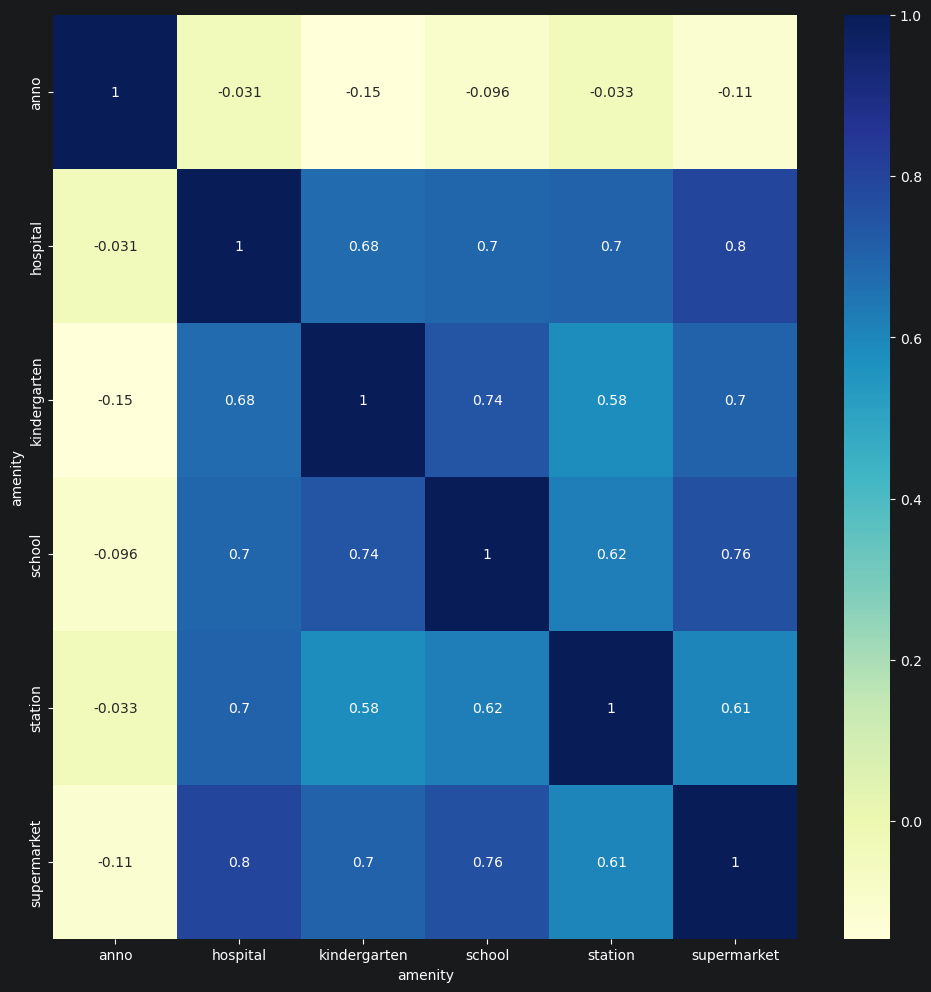

In [498]:
##voglio vdere se in accessibilità abbiamo correlazione
corr = access.corr(numeric_only=True)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))
sns.heatmap(corr, annot=True, cmap="YlGnBu")

In [499]:
##aggiungo l'informazione del meteo anni 80
#clima medio anni 80
climate_80 = (
    meteo[
        meteo["year"].between(1980, 1990)
    ]
    .groupby("comune_norm", as_index=False)
    .agg(
        temp80=("temperature_mean", "mean"),
        snow80=("snowfall_sum", "mean"),
        rain80=("rain_sum", "mean")
    )
)
climate_80

,comune_norm,temp80,snow80,rain80
0,ABBADIA LARIANA,10.123348,12.319470,124.484848
1,AIRUNO,11.311483,5.183712,97.250758
2,ALBAREDO PER SAN MARCO,5.147086,15.724015,121.242424
3,ALBAVILLA,9.221022,5.167803,104.367424
4,ALBESE CON CASSANO,8.299540,5.167803,104.367424
...,...,...,...,...
305,VIGANÒ,10.538596,5.167803,104.367424
306,VILLA DI CHIAVENNA,7.576769,24.792727,69.372727
307,VILLA DI TIRANO,8.312314,32.132121,47.643939
308,VILLA GUARDIA,11.074924,4.401515,108.100758


In [500]:
#clima medio recente
climate_now = (
    meteo[
        meteo["year"].between(2015, 2025)
    ]
    .groupby("comune_norm", as_index=False)
    .agg(
        temp_now=("temperature_mean", "mean"),
        snow_now=("snowfall_sum", "mean"),
        rain_now=("rain_sum", "mean")
    )
)
climate_now

,comune_norm,temp_now,snow_now,rain_now
0,ABBADIA LARIANA,12.120831,5.581579,134.094737
1,ADRARA SAN MARTINO,12.267472,1.627213,123.455738
2,ADRARA SAN ROCCO,9.693519,2.565902,126.449180
3,AIRUNO,13.222589,2.070000,137.273684
4,ALBANO SANT'ALESSANDRO,12.854121,0.920328,128.126230
...,...,...,...,...
548,VILMINORE DI SCALVE,4.148844,22.012131,110.203279
549,ZANDOBBIO,13.135795,0.582951,109.567213
550,ZANICA,13.143340,0.675902,118.926230
551,ZELBIO,9.194648,5.727273,136.771970


In [501]:
##cambiamento climatico anni 80 ad anni 2015-2025
climate_change = (
    climate_80
    .merge(climate_now,on="comune_norm")
)

climate_change["delta_temp"] = (
    climate_change["temp_now"]
    - climate_change["temp80"]
)

climate_change["delta_snow"] = (
    climate_change["snow_now"]
    - climate_change["snow80"]
)

climate_change["delta_rain"] = (
    climate_change["rain_now"]
    - climate_change["rain80"]
)

In [502]:
climate_change

,comune_norm,temp80,snow80,rain80,temp_now,snow_now,rain_now,delta_temp,delta_snow,delta_rain
0,ABBADIA LARIANA,10.123348,12.319470,124.484848,12.120831,5.581579,134.094737,1.997483,-6.737891,9.609888
1,AIRUNO,11.311483,5.183712,97.250758,13.222589,2.070000,137.273684,1.911106,-3.113712,40.022927
2,ALBAREDO PER SAN MARCO,5.147086,15.724015,121.242424,6.924597,19.793561,108.438636,1.777511,4.069545,-12.803788
3,ALBAVILLA,9.221022,5.167803,104.367424,11.835510,3.157424,130.875000,2.614488,-2.010379,26.507576
4,ALBESE CON CASSANO,8.299540,5.167803,104.367424,10.663904,3.364773,130.875758,2.364364,-1.803030,26.508333
...,...,...,...,...,...,...,...,...,...,...
305,VIGANÒ,10.538596,5.167803,104.367424,12.859319,2.034737,138.978947,2.320723,-3.133066,34.611523
306,VILLA DI CHIAVENNA,7.576769,24.792727,69.372727,10.224334,14.295909,100.746970,2.647564,-10.496818,31.374242
307,VILLA DI TIRANO,8.312314,32.132121,47.643939,11.441121,23.320076,94.075758,3.128807,-8.812045,46.431818
308,VILLA GUARDIA,11.074924,4.401515,108.100758,13.093343,2.321136,129.359848,2.018419,-2.080379,21.259091


In [503]:
target = df[df["anno"] == 2025]

target

,COMUNE,anno,hospital,kindergarten,school,station,supermarket,comune_norm,comune_x,temp_mean,...,growth_rate,pop_2015,growth_since_2015,spopolamento,anziani,giovani,bambini,share_anziani,share_giovani,indice_vecchiaia
10,Abbadia Lariana,2025,7.331611,4.148257,4.363710,5.632694,4.887196,ABBADIA LARIANA,Abbadia Lariana,11.994423,...,-0.007217,3234.0,-0.021645,0,846.0,532.0,412.0,0.267383,0.168142,2.053398
21,Adrara San Martino,2025,9.143484,2.804261,2.990381,10.034796,3.406592,ADRARA SAN MARTINO,Adrara San Martino,12.032469,...,0.017584,2193.0,0.002736,0,418.0,462.0,345.0,0.190086,0.210095,1.211594
32,Adrara San Rocco,2025,16.907247,8.928201,9.114321,17.798558,11.170354,ADRARA SAN ROCCO,Adrara San Rocco,9.412544,...,0.009913,854.0,-0.045667,0,199.0,139.0,117.0,0.244172,0.170552,1.700855
43,Airuno,2025,7.649700,4.835162,5.213913,1.387889,5.143533,AIRUNO,Airuno,13.293945,...,0.005579,2882.0,0.000694,0,688.0,541.0,452.0,0.238558,0.187587,1.522124
65,Albaredo per San Marco,2025,17.466644,18.305195,18.128420,18.352371,5.554621,ALBAREDO PER SAN MARCO,Albaredo per San Marco,6.754462,...,-0.010101,323.0,-0.089783,1,103.0,45.0,23.0,0.350340,0.153061,4.478261
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6082,Villa di Tirano,2025,5.609354,4.406797,1.572274,5.214367,1.573241,VILLA DI TIRANO,Villa di Tirano,10.850250,...,0.004008,3007.0,-0.000333,0,755.0,543.0,460.0,0.251164,0.180639,1.641304
6115,Vilminore di Scalve,2025,10.891151,0.000000,2.436182,25.970256,20.666038,VILMINORE DI SCALVE,Vilminore di Scalve,4.436870,...,-0.002786,1481.0,-0.033086,0,383.0,238.0,213.0,0.267458,0.166201,1.798122
6126,Zandobbio,2025,5.261914,9.563982,6.725948,10.116890,6.519142,ZANDOBBIO,Zandobbio,13.056864,...,0.010037,2755.0,-0.013793,0,574.0,507.0,444.0,0.211262,0.186603,1.292793
6148,Zelbio,2025,29.095393,11.824886,11.544828,21.305906,20.513450,ZELBIO,Zelbio,9.006004,...,-0.005405,211.0,-0.127962,1,39.0,32.0,23.0,0.211957,0.173913,1.695652


In [504]:
analysis_df = (
    target
    .merge(
        climate_change,
        left_on="comune_norm",
        right_on="comune_norm",
        how="left"
    )
)

In [505]:
analysis_df.columns

Index(['COMUNE', 'anno', 'hospital', 'kindergarten', 'school', 'station',
       'supermarket', 'comune_norm', 'comune_x', 'temp_mean', 'rain_sum',
       'snow_sum', 'temp_sd', 'rain_sd', 'n_snow_months', 'winter_temp_mean',
       'n_heavy_rain_months', 'snow_3y', 'id_demo', 'comune_y', 'provincia',
       'm_anno_0', 'f_anno_0', 't_anno_0', 'm_0_5_prima_infanzia',
       'm_6_11_infanzia', 'm_12_17_adolescenza', 'm_18_24_giovani_adulti',
       'm_25_34_adulti_giovani', 'm_35_44_adulti', 'm_45_54_adulti_maturi',
       'm_55_64_pre_senior', 'm_65_74_senior', 'm_75_e_oltre_anziani',
       'f_0_5_prima_infanzia', 'f_6_11_infanzia', 'f_12_17_adolescenza',
       'f_18_24_giovani_adulti', 'f_25_34_adulti_giovani', 'f_35_44_adulti',
       'f_45_54_adulti_maturi', 'f_55_64_pre_senior', 'f_65_74_senior',
       'f_75_e_oltre_anziani', 't_0_5_prima_infanzia', 't_6_11_infanzia',
       't_12_17_adolescenza', 't_18_24_giovani_adulti',
       't_25_34_adulti_giovani', 't_35_44_adulti', 't_45

In [506]:
##provo a fare analisi con questo
vars_to_check = [
   "latitudine",
    "delta_temp",
    "delta_snow",
    "delta_rain",
    "hospital",
    "station",
    "supermarket",
    "share_anziani",
    "share_giovani"
    ,"spopolamento"
]

In [507]:
ml_df = analysis_df[vars_to_check].copy()
ml_df.columns

Index(['latitudine', 'delta_temp', 'delta_snow', 'delta_rain', 'hospital',
       'station', 'supermarket', 'share_anziani', 'share_giovani',
       'spopolamento'],
      dtype='object')

In [508]:
ml_df = ml_df.dropna()

In [509]:
import statsmodels.api as sm

X = ml_df[[
     "latitudine",
    "delta_temp",
    "delta_snow",
    "delta_rain",
    "hospital",
    "station",
    "supermarket",
    "share_giovani","share_anziani"]]

X = sm.add_constant(X)

y = ml_df["spopolamento"]

logit = sm.Logit(y, X).fit()

print(logit.summary())


Optimization terminated successfully.
         Current function value: 0.476221
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           spopolamento   No. Observations:                  234
Model:                          Logit   Df Residuals:                      224
Method:                           MLE   Df Model:                            9
Date:                Sat, 13 Jun 2026   Pseudo R-squ.:                  0.2368
Time:                        19:20:18   Log-Likelihood:                -111.44
converged:                       True   LL-Null:                       -146.02
Covariance Type:            nonrobust   LLR p-value:                 2.223e-11
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -52.0634     47.130     -1.105      0.269    -144.436      40.310
latitudine     7.779

In [510]:
X.columns

Index(['const', 'latitudine', 'delta_temp', 'delta_snow', 'delta_rain',
       'hospital', 'station', 'supermarket', 'share_giovani', 'share_anziani'],
      dtype='object')